In [32]:
import pandas as pd

In [ ]:
df = pd.read_csv('/kaggle/input/suicide-watch/Suicide_Detection.csv')
df.head()

In [34]:
df.drop(columns = 'Unnamed: 0' , inplace = True)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232074 entries, 0 to 232073
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    232074 non-null  object
 1   class   232074 non-null  object
dtypes: object(2)
memory usage: 3.5+ MB


In [36]:
df['class'].replace({'suicide':1 , 'non-suicide':0} , inplace = True)

In [37]:
from bs4 import BeautifulSoup

def strip_html_tags(text):
  soup = BeautifulSoup(text, "html.parser")
  [s.extract() for s in soup(['iframe', 'script'])]
  stripped_text = soup.get_text()
  stripped_text = re.sub(r'[\r|\n|\r\n]+', '\n', stripped_text)
  return stripped_text

def remove_accented_chars(text):
  text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8', 'ignore')
  return text

def stopwords_removal(words):
    list_stopwords = nltk.corpus.stopwords.words('english')
    return [word for word in words if word not in list_stopwords]

In [ ]:
!pip install contractions

In [39]:
import re
import nltk
import tqdm
import unicodedata
import contractions

from nltk.tokenize import word_tokenize

def pre_process_corpus(docs):
  norm_docs = []
  for doc in tqdm.tqdm(docs):
    #case folding
    doc = doc.lower()
    #remove special characters\whitespaces
    doc = strip_html_tags(doc)
    doc = doc.translate(doc.maketrans("\n\t\r", "   "))
    doc = remove_accented_chars(doc)
    doc = contractions.fix(doc)
    doc = re.sub(r'[^a-zA-Z0-9\s]', '', doc, re.I|re.A)
    doc = re.sub(' +', ' ', doc)
    doc = doc.strip()
    #tokenize
    doc = word_tokenize(doc)
    #filtering
    doc = stopwords_removal(doc)
    norm_docs.append(doc)
  
  norm_docs = [" ".join(word) for word in norm_docs]
  return norm_docs

In [40]:
%%time
df.text = pre_process_corpus(df.text)

  0%|          | 0/232074 [00:00<?, ?it/s]<ipython-input-37-be5d0f72bd36>:4: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  soup = BeautifulSoup(text, "html.parser")
100%|██████████| 232074/232074 [04:34<00:00, 846.70it/s] 


CPU times: user 4min 27s, sys: 8.28 s, total: 4min 35s
Wall time: 4min 34s


In [ ]:
df.head()

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df.text, df['class'], test_size=0.2, random_state=42)
X_train.shape , X_test.shape, y_train.shape, y_test.shape

((185659,), (46415,), (185659,), (46415,))

In [43]:
import keras
import tensorflow as tf

t = tf.keras.preprocessing.text.Tokenizer(oov_token='<UNK>')
# fit the tokenizer on the documents
t.fit_on_texts(X_test)
t.word_index['<PAD>'] = 0

In [44]:
train_sequences = t.texts_to_sequences(X_train)
test_sequences = t.texts_to_sequences(X_test)

In [45]:
VOCAB_SIZE = len(t.word_index)

print("Vocabulary size={}".format(len(t.word_index)))
print("Number of Documents={}".format(t.document_count))

Vocabulary size=77430
Number of Documents=46415


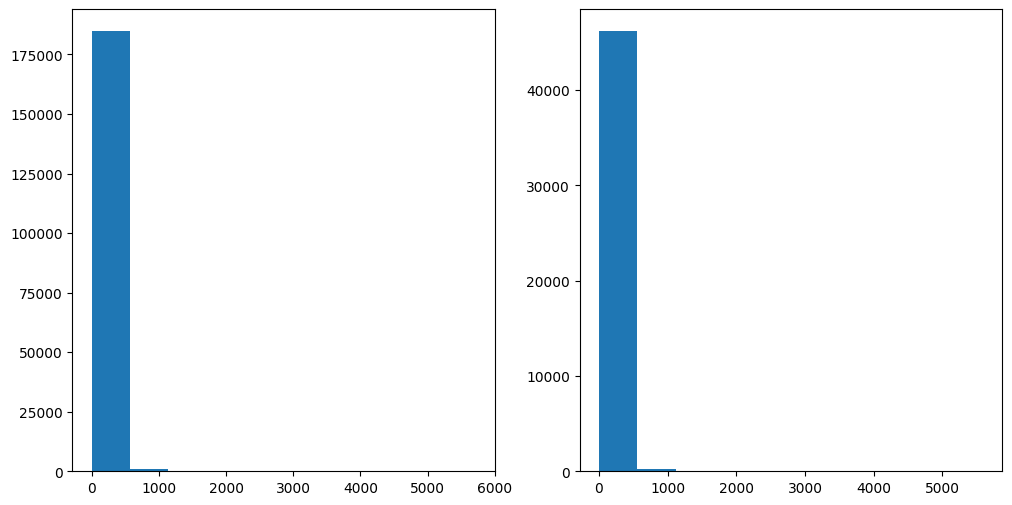

In [46]:
import matplotlib.pyplot as plt
%matplotlib inline

train_lens = [len(s) for s in train_sequences]
test_lens = [len(s) for s in test_sequences]

fig, ax = plt.subplots(1,2, figsize=(12, 6))
h1 = ax[0].hist(train_lens)
h2 = ax[1].hist(test_lens)

In [47]:
MAX_SEQUENCE_LENGTH = 200

from keras.preprocessing.sequence import pad_sequences
# pad dataset to a maximum review length in words
X_train = pad_sequences(train_sequences, maxlen=MAX_SEQUENCE_LENGTH)
X_test = pad_sequences(test_sequences, maxlen=MAX_SEQUENCE_LENGTH)
X_train.shape, X_test.shape

((185659, 200), (46415, 200))

In [48]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
num_classes=2 

In [49]:
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [50]:
from tensorflow.keras.layers import Layer
from tensorflow.keras import backend as K
from tensorflow.keras.initializers import glorot_uniform
from tensorflow.keras.regularizers import get as regularizer_get
from tensorflow.keras.constraints import get as constraint_get

class AttentionLayer(Layer):
    
    def __init__(self, step_dim,
                 W_regularizer=None, b_regularizer=None,
                 W_constraint=None, b_constraint=None,
                 bias=True, **kwargs):
        
        self.supports_masking = True
        self.init = glorot_uniform()

        self.W_regularizer = regularizer_get(W_regularizer)
        self.b_regularizer = regularizer_get(b_regularizer)

        self.W_constraint = constraint_get(W_constraint)
        self.b_constraint = constraint_get(b_constraint)

        self.bias = bias
        self.step_dim = step_dim
        self.features_dim = 0
        super(AttentionLayer, self).__init__(**kwargs)
        

    def build(self, input_shape):
        assert len(input_shape) == 3

        self.W = self.add_weight(shape=(input_shape[-1],),
                                 initializer=self.init,
                                 name='{}_W'.format(self.name),
                                 regularizer=self.W_regularizer,
                                 constraint=self.W_constraint)
        self.features_dim = input_shape[-1]

        if self.bias:
            self.b = self.add_weight(shape=(input_shape[1],),
                                     initializer='zeros',
                                     name='{}_b'.format(self.name),
                                     regularizer=self.b_regularizer,
                                     constraint=self.b_constraint)
        else:
            self.b = None

        self.built = True
        

    def compute_mask(self, input, input_mask=None):
        return None

    
    def call(self, x, mask=None):
        features_dim = self.features_dim
        step_dim = self.step_dim

        eij = K.reshape(K.dot(K.reshape(x, (-1, features_dim)), 
                              K.reshape(self.W, (features_dim, 1))),
                        (-1, step_dim))

        if self.bias:
            eij += self.b

        eij = K.tanh(eij)

        a = K.exp(eij)

        if mask is not None:
            a *= K.cast(mask, K.floatx())

        a /= K.cast(K.sum(a, axis=1, keepdims=True) + K.epsilon(), K.floatx())
        a = K.expand_dims(a)
        weighted_input = x * a
        
        return K.sum(weighted_input, axis=1)

    
    def compute_output_shape(self, input_shape):
        return input_shape[0],  self.features_dim
    
    
    def get_config(self):
        config = {'step_dim': self.step_dim}
        base_config = super(AttentionLayer, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))


In [51]:
import keras
from keras import initializers, regularizers, constraints, optimizers, layers
from keras.models import Model
from keras.layers import Input, Embedding, Bidirectional,LSTM,GRU ,Concatenate, Dense, Dropout, LSTM

EMBEDDING_DIM = 200 # dimension for dense embeddings for each token
LSTM_DIM = 50 # total LSTM units

sequence_input = Input(shape=(MAX_SEQUENCE_LENGTH,))
embedded_sequences = Embedding(VOCAB_SIZE, EMBEDDING_DIM, trainable=True)(sequence_input)
bilstm = Bidirectional(LSTM(LSTM_DIM, return_sequences=True))(embedded_sequences)
#bigru = keras.layers.Bidirectional(keras.layers.GRU(GRU_DIM, return_sequences=True, recurrent_dropout=0.2))(embedded_sequences)
att = AttentionLayer(MAX_SEQUENCE_LENGTH)(bilstm)
dense1 = Dense(LSTM_DIM*2, activation='relu')(att)
dropout1 = Dropout(rate=0.30)(dense1)

outp = keras.layers.Dense(1, activation='sigmoid')(dense1)
# initialize the model
model = keras.models.Model(inputs=sequence_input, outputs=outp)

    
model.compile(loss='binary_crossentropy', optimizer=optimizers.Adam(learning_rate=0.0001), metrics=['accuracy'])

In [52]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding_1 (Embedding)              │ (None, 200, 200)            │      15,486,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 200, 100)            │         100,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ attention_layer_1 (AttentionLayer)   │ (None, 100)                 │             300 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 100)                 │          10,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,596,901 (59.50 MB)

 Trainable params: 15,596,901 (59.50 MB)

 Non-trainable params: 0 (0.00 B)

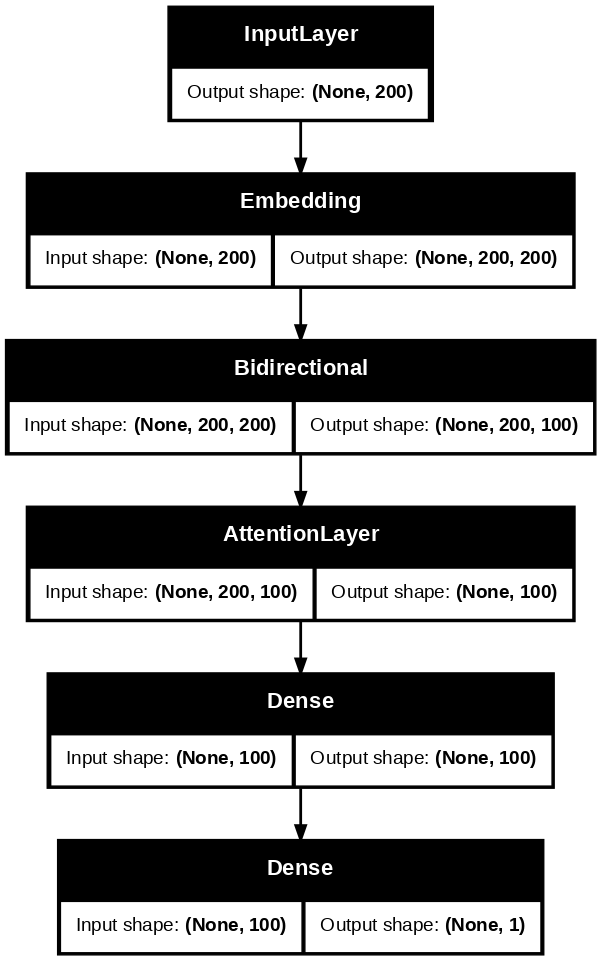

In [53]:
keras.utils.plot_model(model, show_shapes=True, dpi = 100)

In [54]:
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint

epochs = 100
batch_size = 128

es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=10)
mc = ModelCheckpoint('./best_model/best_model_gru.keras', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)
history = model.fit(X_train, y_train,  batch_size=batch_size, shuffle=True, validation_split=0.1, epochs=epochs, verbose=1, callbacks=[es, mc])

Epoch 1/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7967 - loss: 0.4100
Epoch 1: val_accuracy improved from -inf to 0.93456, saving model to ./best_model/best_model_gru.keras
1306/1306 ━━━━━━━━━━━━━━━━━━━━ 51s 37ms/step - accuracy: 0.7968 - loss: 0.4098 - val_accuracy: 0.9346 - val_loss: 0.1716
Epoch 2/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9406 - loss: 0.1589
Epoch 2: val_accuracy improved from 0.93456 to 0.94468, saving model to ./best_model/best_model_gru.keras
1306/1306 ━━━━━━━━━━━━━━━━━━━━ 48s 37ms/step - accuracy: 0.9406 - loss: 0.1588 - val_accuracy: 0.9447 - val_loss: 0.1468
Epoch 3/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9551 - loss: 0.1240
Epoch 3: val_accuracy improved from 0.94468 to 0.94770, saving model to ./best_model/best_model_gru.keras
1306/1306 ━━━━━━━━━━━━━━━━━━━━ 49s 37ms/step - accuracy: 0.9551 - loss: 0.1240 - val_accuracy: 0.9477 - val_loss: 0.1349
Epoch 4/100
1305/1306 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/s

In [55]:
from keras.models import load_model

# Final evaluation of the model
# load the saved model
saved_model = load_model('./best_model/best_model_gru.keras', custom_objects={'AttentionLayer': AttentionLayer})
train_acc = saved_model.evaluate(X_train, y_train, verbose=1)
test_acc = saved_model.evaluate(X_test, y_test, verbose=1)
print('Train: %.2f%%, Test: %.2f%%' % (train_acc[1]*100, test_acc[1]*100))

5802/5802 ━━━━━━━━━━━━━━━━━━━━ 53s 9ms/step - accuracy: 0.9906 - loss: 0.0310
1451/1451 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9317 - loss: 0.2333
Train: 98.72%, Test: 93.14%


dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


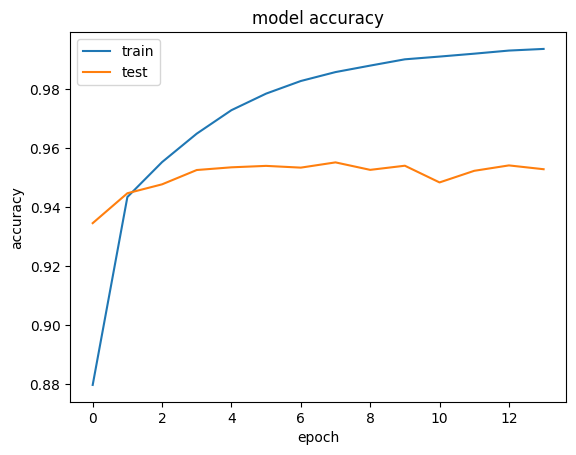

In [56]:
# list all data in history
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.savefig('model accuracy dropout 0.5 balance.jpg')
plt.show()

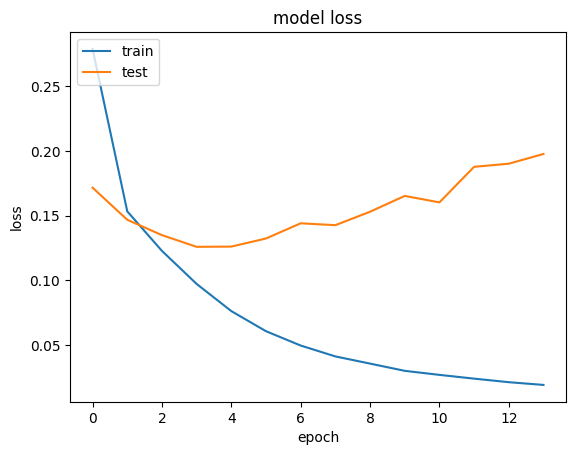

In [57]:
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.savefig('model loss dropout 0.5 balance.jpg')
plt.show()

In [58]:
prediction_probs = model.predict(X_test, verbose=1).ravel()
predictions = [1 if prob > 0.5 else 0 for prob in prediction_probs]

1451/1451 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step


In [59]:
from sklearn.metrics import confusion_matrix, classification_report

labels = ['positive', 'negative']
print(classification_report(y_test, predictions))
pd.DataFrame(confusion_matrix(y_test, predictions), index=labels, columns=labels)

              precision    recall  f1-score   support

           0       0.91      0.96      0.94     23287
           1       0.96      0.91      0.93     23128

    accuracy                           0.93     46415
   macro avg       0.94      0.93      0.93     46415
weighted avg       0.94      0.93      0.93     46415



,positive,negative
positive,22344,943
negative,2110,21018


In [60]:
from sklearn.metrics import roc_auc_score, roc_curve

def plot_roc_curve(y_test, y_pred):
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    plt.plot(fpr, tpr)
    plt.plot([0, 1], ls="--")
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

model AUC score: 0.9834682892031823


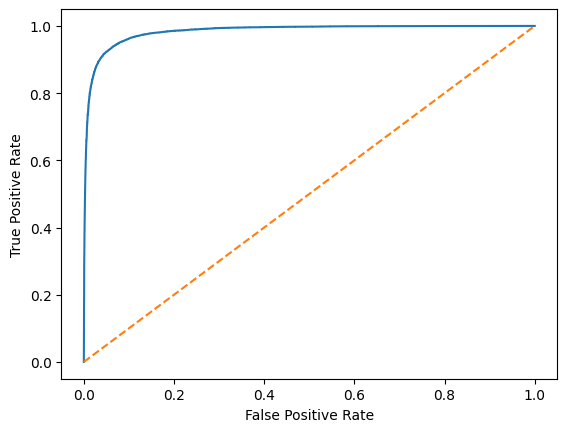

In [61]:
plot_roc_curve(y_test, prediction_probs)
print(f'model AUC score: {roc_auc_score(y_test, prediction_probs)}')

model f1 score: 0.9322894719332875 model AUC score: 0.9824570302883812


Text(0, 0.5, 'Precision')

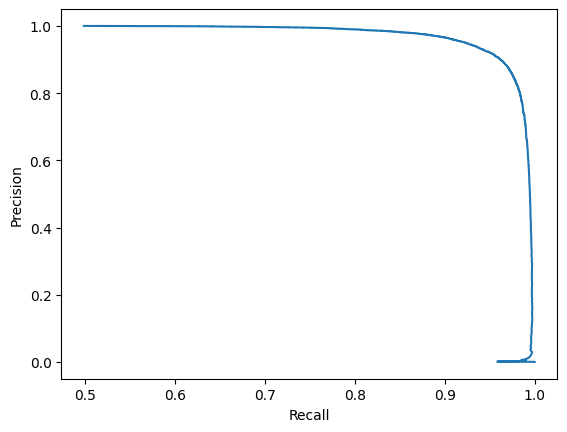

In [62]:
from sklearn.metrics import precision_recall_curve, f1_score, auc

precision, recall, thresholds = precision_recall_curve(y_test, prediction_probs)
print(f'model f1 score: {f1_score(y_test, predictions)} model AUC score: {auc(recall, precision)}')
plt.plot(precision, recall)
plt.xlabel('Recall')
plt.ylabel('Precision')